# V7: score experiments, reliability and understanding

The span uses a fixed 30-hour clock and 24,000-second charged GPU ceiling.
Development and original confirmation are historically inspected. A negative or
deferred experiment is reported explicitly. See the per-task reports and theory
guide; no gain ranges are treated as measurements.


In [1]:
import json,sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
REPO=Path.cwd().resolve()
if not (REPO/'GOAL.md').exists():REPO=REPO.parent
sys.path.insert(0,str(REPO/'src'))
from arena.data import ROOT
PUB=REPO/'results/span_007';RUN=ROOT/'runs/span_007';FIG=RUN/'figures';FIG.mkdir(parents=True,exist_ok=True)
def read(path):return json.loads(Path(path).read_text())
def result(name):
    path=PUB/name
    if name in ['H49_results.json','H48_results.json']:
        recovered=PUB/name.replace('_results.json','_recovered_artifacts_results.json')
        if recovered.exists():path=recovered
    return read(path)
def save(fig,name):
    for suffix in ['png','svg']:fig.savefig(FIG/(name+'.'+suffix),dpi=160,bbox_inches='tight')
    plt.show()
cfg=read(REPO/'configs/span_007.json')

registry=read(REPO/'backlog/hypotheses.json');v7=next(v for v in registry['versions'] if v['number']==7);items={r['id']:r for r in registry['items']}
print('V7 state:',v7['state'],'active version:',registry['active_version'],'deadline:',cfg['deadline'])
display(pd.DataFrame([{'task':i,'status':items[i]['status'],'title':items[i]['title']} for i in v7['focus_ids']]))
print('Fixed charged GPU cap:',cfg['gpu_session_seconds_cap'],'seconds; possible hidden evaluation bounded separately.')


V7 state: closed active version: 8 deadline: 2026-11-07T00:30:17+00:00


,task,status,title
0,E09,done,Reusable experiment control and framework reli...
1,E10,done,Observe every pipeline stage and actual traini...
2,E11,done,Explain pipeline theory and reassess skipped work
3,H49,done,Test bounded additional exposure under an obse...
4,H48,done,Expand the paired context-retention experiment...
5,E05,done,Test native judge sensitivity to request concu...
6,H44,deferred,Calibrate a routed classifier and judge mixture
7,H47,done,Predict source strength directly rather than r...
8,H50,deferred,Qualify and officially evaluate one frozen v7 ...


Fixed charged GPU cap: 24000 seconds; possible hidden evaluation bounded separately.


## Matched preference effects

Each point compares a candidate with its own matched control. Training uses
grouped temperature CV; context uses the fixed temperature; source residuals use
nested fitting. Absolute losses across these recipes are not a model ranking.
Positive gain lowers loss. Intervals condition on saved predictions.


H49 complete artifacts recovered; service status remains ERROR
H48 incomplete: The bounded remote execution failed; retain partial outputs, no promotion.
Verified saved rows by length: {'1024': 1152, '2048': 896} missing long rows: 256 integrity audit: True


,task,recipe,gain,interval_95,groups,rows,replicates,passed
0,H49,temperature_cv,0.001354,"[-0.000283, 0.002969]",5211,5746,2000,False
1,H47,nested residual versus calibration,0.000496,"[-0.000594, 0.001572]",5211,5746,2000,False


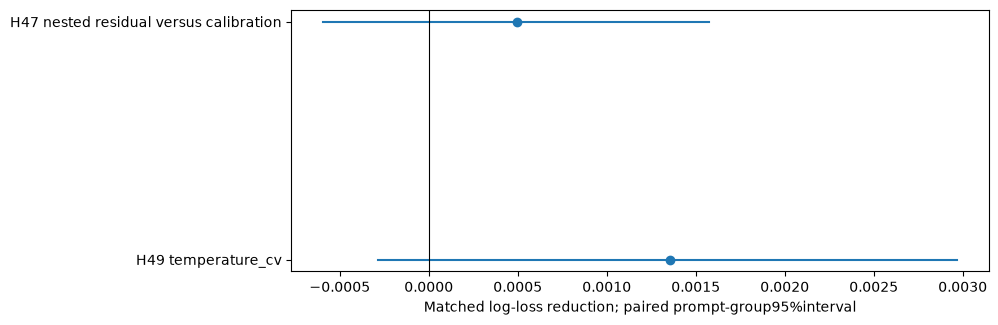

In [2]:
rows=[]
for name in ['H49','H48']:
    r=result(name+'_results.json')
    if r.get('recovered_complete_artifacts'):print(name,'complete artifacts recovered; service status remains',r['service_status'])
    if r.get('complete'):
        g=r['gains'][r['primary']];rows.append({'task':name,'recipe':r['primary'],**g,'passed':r['quality_gate']['passed']})
    else:
        print(name,'incomplete:',r.get('reason'))
        if name=='H48' and (PUB/'context_partial_audit.json').exists():
            coverage=result('context_partial_audit.json')
            print('Verified saved rows by length:',{k:v['rows'] for k,v in coverage['coverage'].items()},'missing long rows:',coverage['missing_long_rows'],'integrity audit:',coverage['passed'])
r=result('H47_results.json');rows.append({'task':'H47','recipe':'nested residual versus calibration',**r['contrasts']['calibration'],'passed':r['gate']['passed']})
display(pd.DataFrame(rows))
fig,ax=plt.subplots(figsize=(9,3.4))
for i,r in enumerate(rows):
    lo,hi=r['interval_95'];ax.plot([lo,hi],[i,i],color='C0');ax.scatter(r['gain'],i,color='C0')
ax.axvline(0,color='black',linewidth=.8);ax.set_yticks(range(len(rows)),[r['task']+' '+r['recipe'] for r in rows]);ax.set_xlabel('Matched log-loss reduction; paired prompt-group95%interval')
save(fig,'v7_matched_gains')


## Source experiment and exact loss decomposition

H47's source outer folds are three, with three inner folds. Preference outer folds
are five. The original prose error and immutable executable are documented in the
erratum. Direct linear regression and identity softmax have different head
capacity despite using the same sparse text features. The tie/winner decomposition
is an identity; channel magnitude alone does not establish causal headroom.


,log_loss,accuracy,tie_auc
calibration,0.953701,0.53881,0.678936
style,0.954809,0.533763,0.677003
direct_strength,0.953205,0.537591,0.67728
posterior_three,0.952434,0.541246,0.677687
old_compact,0.952439,0.539854,0.677671
nested_selected,0.953205,0.537591,0.67728


Source MSE: {'direct': 0.21308851120783245, 'identity': 0.20173141223015031, 'gain': {'gain': -0.011357098977682183, 'interval_95': [-0.012180133825985777, -0.010573381077917384], 'groups': 40828, 'rows': 91970, 'replicates': 2000}} final ridge penalty: 10.0


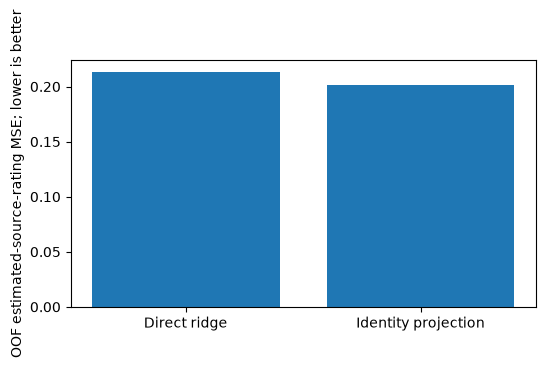

,multiclass_loss,binary_tie_channel,weighted_conditional_winner_channel,conditional_winner_loss_on_decisive_rows,tie_frequency,accuracy
H03_frozen_temperature,0.953971,0.566993,0.386978,0.559953,0.308911,0.537939
v5_calibration,0.953701,0.566796,0.386905,0.559848,0.308911,0.538810
v5_style,0.954809,0.567588,0.387221,0.560306,0.308911,0.533763
v5_source_strength,0.952397,0.567201,0.385195,0.557374,0.308911,0.540898
v5_nested_selected,0.953834,0.568191,0.385643,0.558022,0.308911,0.541072
v5_training_prior,1.097216,0.618226,0.478990,0.693094,0.308911,0.349112
v5_uniform,1.098612,0.619586,0.479027,0.693147,0.308911,0.349112
v5_majority_clipped_1e-12,17.984688,8.535514,9.449174,13.672867,0.308911,0.349112


{'assumption': 'Hard predicted class has alpha; each other class has(1-alpha)/2; optimal alpha equals measured accuracy.', 'accuracy_for_loss_0_8_under_this_assumption': 0.711985969343905, 'not_a_universal_accuracy_requirement': True}


,cohort,view,gain
0,monitor,original_raw,-0.021307
1,monitor,aligned_swap_raw,0.009930
2,monitor,order_average_raw,-0.003733
3,monitor,order_average_frozen_temperature,-0.003852
4,full_development,original_raw,-0.000829
5,full_development,aligned_swap_raw,0.000699
6,full_development,order_average_raw,0.001307
7,full_development,order_average_frozen_temperature,0.001391


Raw loss averaging identity: {'monitor': {'mean_single_view_loss_before': 0.9525153584558759, 'mean_single_view_loss_after': 0.9582040087398004, 'reference_averaging_benefit': 0.010517983005201348, 'candidate_averaging_benefit': 0.01247389287679146, 'mean_single_view_gain': -0.005688650283924512, 'change_in_averaging_benefit': 0.0019559098715901113, 'order_averaged_gain': -0.003732740412334401}, 'full_development': {'mean_single_view_loss_before': 0.9657780281157033, 'mean_single_view_loss_after': 0.9658428783818741, 'reference_averaging_benefit': 0.011442532744112444, 'candidate_averaging_benefit': 0.01281393938339459, 'mean_single_view_gain': -6.485026617075729e-05, 'change_in_averaging_benefit': 0.0013714066392821467, 'order_averaged_gain': 0.0013065563731113894}}


In [3]:
source=result('H47_results.json');display(pd.DataFrame(source['preference_metrics']).T[['log_loss','accuracy','tie_auc']])
print('Source MSE:',source['source_mse'],'final ridge penalty:',source['final_alpha'])
fig,ax=plt.subplots(figsize=(6,3.2));ax.bar(['Direct ridge','Identity projection'],[source['source_mse']['direct'],source['source_mse']['identity']]);ax.set_ylabel('OOF estimated-source-rating MSE; lower is better');save(fig,'v7_source_mse')
pipeline=result('pipeline_analysis.json');display(pd.DataFrame(pipeline['decomposition']).T)
print(pipeline['constant_confidence_model'])
if (PUB/'monitor_alignment.json').exists():
    alignment=result('monitor_alignment.json')
    display(pd.DataFrame([{'cohort':c,'view':v,'gain':r['paired_gain']['gain']} for c,m in alignment['cohorts'].items() for v,r in m.items()]))
    print('Raw loss averaging identity:',result('order_averaging_decomposition.json')['cohorts'])


## Native numerical stability and actual resources

The native server configuration stays fixed; client concurrency is the tested
factor. Serial stability is distinct from affordable deployment. No calibration
may use an incompatible old cache. Resource bars include setup and failures.
Unexecuted work has zero charge, not an invented quality estimate.


,case,concurrency,stable,seconds_per_row,projected_cascade_seconds,eligible
0,parallel,16,False,1.311166,28332.143405,False
1,serial,1,True,1.023580,26606.624690,False


,role,charged_seconds,cap_seconds,stage
0,continuation,9888.946,13200,failed
1,context,2603.023,2700,failed
2,judge_stability,838.613,2400,complete
3,judge_cache,0.000,1200,not executed
4,promotion,0.000,4500,not executed


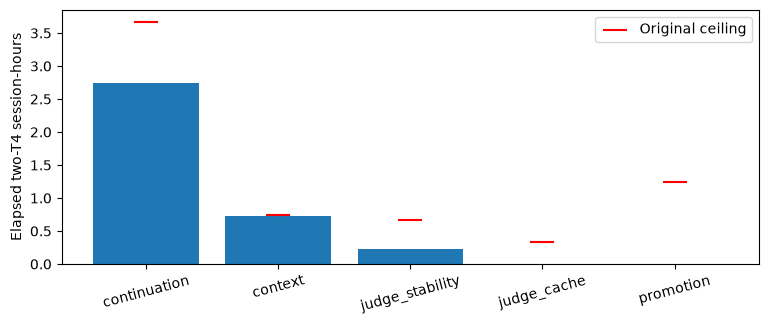

H47 CPU: 1872.7038477880415 seconds; RSS: 3.4103317260742188 GiB


In [4]:
judge=result('E05_results.json')
if judge.get('complete'):
    display(pd.DataFrame([{'case':name,'concurrency':v['concurrency'],'stable':v['repeatability_passed'],'seconds_per_row':v['seconds_per_row'],'projected_cascade_seconds':v['projected_cascade_seconds'],'eligible':v['eligible']} for name,v in judge['configurations'].items()]))
else:print(judge)
charges=[]
for role,cap in cfg['job_seconds_caps'].items():
    p=PUB/'jobs'/role/'controller_state.json';state=read(p) if p.exists() else {}
    charges.append({'role':role,'charged_seconds':state.get('charged_seconds',0),'cap_seconds':cap,'stage':state.get('stage','not executed')})
display(pd.DataFrame(charges));fig,ax=plt.subplots(figsize=(9,3.3));x=np.arange(len(charges));ax.bar(x,[r['charged_seconds']/3600 for r in charges]);ax.scatter(x,[r['cap_seconds']/3600 for r in charges],marker='_',s=300,color='red',label='Original ceiling');ax.set_xticks(x,[r['role'] for r in charges],rotation=15);ax.set_ylabel('Elapsed two-T4 session-hours');ax.legend();save(fig,'v7_compute')
print('H47 CPU:',source['cpu_seconds'],'seconds; RSS:',source['peak_rss_gib'],'GiB')


## Promotion, audits and version boundary

Read the frozen candidate selection and H50 result for actual confirmation,
offline qualification and official evaluation. There is at most one submission;
no leaderboard tuning. Framework tests, actual exposure audits and preserved
snapshots are independent checks, not model quality measurements.


In [5]:
for name in ['candidate_selection.json','H50_results.json','H47_audit.json','training_audit.json','judge_audit.json','terminal_audit.json','decisions.json','validation.json']:
    p=PUB/name
    if p.exists():
        value=read(p);print(name,{k:v for k,v in value.items() if k not in ['artifact_sha256','output_sha256','input_sha256','inventory','jobs','test_sha256','test_and_program_sha256']})
display(pd.DataFrame([{'version':v['number'],'state':v['state'],'tasks':len(v['item_ids']),'focus':v['focus_ids']} for v in registry['versions']]))
print('Standalone figures:',FIG)


candidate_selection.json {'frozen_at': '2026-11-05T22:37:25.625661+00:00', 'eligible': False, 'candidate_kind': None, 'priority': ['continuation', 'context'], 'confirmation_targets_used': False, 'rule': 'Training first if its frozen quality/runtime gate passes, otherwise context if it passes.', 'input_paths': {'continuation': 'results/span_007/H49_recovered_artifacts_results.json', 'context': 'results/span_007/H48_results.json'}, 'source_sha256': '15141e90430fb7f3d872758afa0254a8d40b53bc4b3e62626ebfbfed1a700904'}
H50_results.json {'task': 'H50', 'executed': False, 'status': 'deferred', 'passed': False, 'charged_gpu_seconds': 0, 'reason': 'Neither frozen classifier candidate passed its predeclared quality/runtime gates. No confirmation qualification or official submission was executed.', 'at': '2026-11-05T22:46:06.450662+00:00'}
H47_audit.json {'passed': True, 'checked_at': '2026-11-05T20:05:59.691952+00:00', 'source_outer_folds': 3, 'preference_outer_folds': 5, 'source_predictions_repl

,version,state,tasks,focus
0,1,closed,41,"[E00, H01, H09, H04, H11]"
1,2,closed,39,"[H40, E01, H03, H37, H42]"
2,3,closed,37,"[E03, H39, E02, H43]"
3,4,closed,35,"[E04, H44]"
4,5,closed,38,"[E06, E07, H45]"
5,6,closed,37,"[H46, E08]"
6,7,closed,43,"[E09, E10, E11, H49, H48, E05, H44, H47, H50]"
7,8,active,40,[]
8,9,draft,0,[]


Standalone figures: /home/tarstars/database/llm_classification_finetuning/runs/span_007/figures
